<a href="https://colab.research.google.com/github/abdealimak/ML-CW/blob/main/Email_Spam_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Email Spam Detection using Logistic Regression

**Problem statement:** Build a model that predicts whether an email is spam or not spam.

**Dataset:** An email dataset with numerical features (word counts, suspicious link counts, spam indicator words etc.) and a binary target (1 = spam, 0 = not spam).

**Note:** the csv file name and the target column name are set in one place in the first code cell below, so if you want to run this on a different email dataset only those two lines need to be changed.

## Importing libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)

## Loading and looking at the data

In [2]:
FILE_NAME = 'email_spam_dataset.csv'
TARGET = 'is_spam'

df = pd.read_csv(FILE_NAME)
df.head(10)

,word_count,num_links,suspicious_links,exclamation_marks,free_count,money_words,urgent_words,all_caps_words,has_attachment,sender_known,is_spam
0,222,1,1,1,1,0,0,2,0,1,0
1,82,1,1,0,0,0,0,2,0,1,0
2,170,1,0,1,0,1,0,0,0,1,0
3,181,4,2,3,0,1,3,2,0,0,1
4,111,4,5,5,4,1,3,4,1,0,1
5,316,3,0,1,0,0,0,1,0,1,0
6,121,5,0,2,3,2,0,5,1,0,1
7,127,1,0,1,1,0,0,0,0,1,0
8,163,2,0,1,0,0,0,2,0,0,0
9,67,1,0,1,1,0,0,0,1,0,0


In [3]:
print("Rows, columns:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Rows, columns: (1000, 11)
Missing values: 0
Duplicate rows: 3


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
word_count,1000.0,152.100,74.465489,15.0,98.0,147.5,203.0,396.0
num_links,1000.0,2.124,1.879936,0.0,1.0,2.0,3.0,10.0
suspicious_links,1000.0,0.787,1.123786,0.0,0.0,0.0,1.0,7.0
exclamation_marks,1000.0,1.880,1.919710,0.0,0.0,1.0,3.0,11.0
free_count,1000.0,1.044,1.401438,0.0,0.0,0.0,2.0,7.0
money_words,1000.0,1.311,1.562280,0.0,0.0,1.0,2.0,8.0
urgent_words,1000.0,0.735,1.026562,0.0,0.0,0.0,1.0,7.0
all_caps_words,1000.0,2.165,2.020361,0.0,1.0,2.0,3.0,9.0
has_attachment,1000.0,0.229,0.420399,0.0,0.0,0.0,0.0,1.0
sender_known,1000.0,0.390,0.487994,0.0,0.0,0.0,1.0,1.0


In [5]:
counts = df[TARGET].value_counts()
print("Not spam (0):", counts[0])
print("Spam (1)    :", counts[1])
print("Spam percentage:", round(counts[1] / len(df) * 100, 1), "%")

Not spam (0): 604
Spam (1)    : 396
Spam percentage: 39.6 %


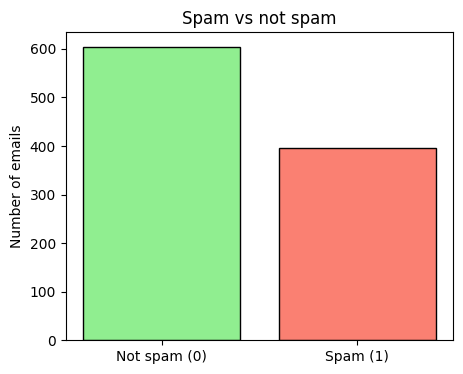

In [6]:
plt.figure(figsize=(5, 4))
plt.bar(['Not spam (0)', 'Spam (1)'], [counts[0], counts[1]], color=['lightgreen', 'salmon'], edgecolor='black')
plt.ylabel('Number of emails')
plt.title('Spam vs not spam')
plt.show()

There are no missing values or duplicates, so no cleaning is needed. The classes are a little imbalanced (more legitimate emails than spam), which is normal for email data. Because of this, plain accuracy can be misleading, and I will come back to that when evaluating the model.

---
## Task 1: Separate features and target

In [7]:
X = df.drop(columns=TARGET)
y = df[TARGET]

print("Features:", list(X.columns))
print("Target  :", TARGET)
print("X shape :", X.shape)
print("y shape :", y.shape)

Features: ['word_count', 'num_links', 'suspicious_links', 'exclamation_marks', 'free_count', 'money_words', 'urgent_words', 'all_caps_words', 'has_attachment', 'sender_known']
Target  : is_spam
X shape : (1000, 10)
y shape : (1000,)


## Task 2: Split into training and testing sets

80% of the data is used for training and 20% for testing. I used `stratify=y` so that the spam percentage is about the same in both parts, which matters when the classes are not balanced.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)
print("Spam share in train:", round(y_train.mean(), 3))
print("Spam share in test :", round(y_test.mean(), 3))

Training set: (800, 10)
Testing set : (200, 10)
Spam share in train: 0.396
Spam share in test : 0.395


## Task 3: Train Logistic Regression

In [9]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [10]:
# coefficients, to see which features push an email towards spam
coef_table = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_[0]})
coef_table.sort_values('Coefficient', ascending=False)

,Feature,Coefficient
2,suspicious_links,0.931443
5,money_words,0.805689
4,free_count,0.662673
7,all_caps_words,0.476662
6,urgent_words,0.247072
3,exclamation_marks,0.201209
1,num_links,0.133956
0,word_count,-0.007083
8,has_attachment,-0.173647
9,sender_known,-0.804255


A positive coefficient means that a higher value of that feature increases the chance of the email being spam, and a negative coefficient decreases it. Suspicious links, money words and "free" words push the prediction towards spam, while an email from a known sender pushes it strongly towards not spam, which makes sense.

## Task 4: Predict class labels and probabilities

In [11]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

# predict_proba gives two columns: [P(not spam), P(spam)]
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred,
    'P(not spam)': y_prob[:, 0].round(3),
    'P(spam)': y_prob[:, 1].round(3)})
results.head(10)

,Actual,Predicted,P(not spam),P(spam)
0,1,1,0.376,0.624
1,0,0,0.986,0.014
2,1,1,0.086,0.914
3,0,0,0.894,0.106
4,1,1,0.007,0.993
5,0,0,0.961,0.039
6,0,0,0.656,0.344
7,1,1,0.029,0.971
8,1,1,0.072,0.928
9,0,0,0.970,0.030


`predict()` returns the final label (0 or 1), while `predict_proba()` returns how confident the model is. The label is simply decided by the probability of spam: if P(spam) is 0.5 or more the email is labelled spam, otherwise not spam. For example, an email with P(spam) = 0.97 is almost certainly spam, while one with 0.52 is a borderline case that just crossed the threshold. This extra information is useful because it lets us decide how strict the filter should be.

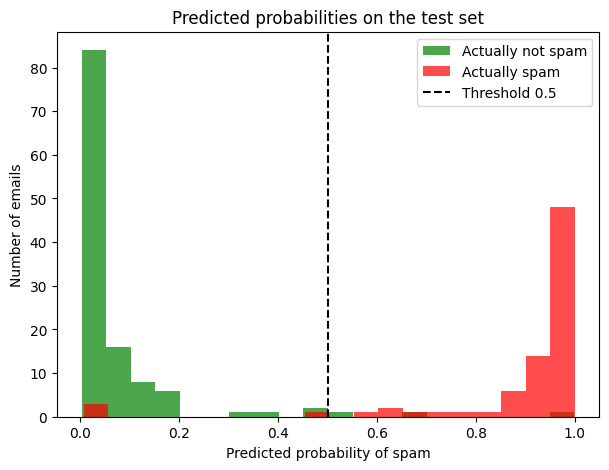

In [12]:
prob_spam = y_prob[:, 1]

plt.figure(figsize=(7, 5))
plt.hist(prob_spam[y_test == 0], bins=20, alpha=0.7, color='green', label='Actually not spam')
plt.hist(prob_spam[y_test == 1], bins=20, alpha=0.7, color='red', label='Actually spam')
plt.axvline(0.5, color='black', linestyle='--', label='Threshold 0.5')
plt.xlabel('Predicted probability of spam')
plt.ylabel('Number of emails')
plt.title('Predicted probabilities on the test set')
plt.legend()
plt.show()

Most legitimate emails get a probability near 0 and most spam emails get one near 1, so the model separates the two groups well. The few emails sitting in the middle are the ones it gets wrong or is unsure about.

## Task 5: Confusion matrix

In [13]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

tn, fp, fn, tp = cm.ravel()
print()
print("True negatives  (not spam, predicted not spam):", tn)
print("False positives (not spam, predicted spam)    :", fp)
print("False negatives (spam, predicted not spam)    :", fn)
print("True positives  (spam, predicted spam)        :", tp)

[[118   3]
 [  4  75]]

True negatives  (not spam, predicted not spam): 118
False positives (not spam, predicted spam)    : 3
False negatives (spam, predicted not spam)    : 4
True positives  (spam, predicted spam)        : 75


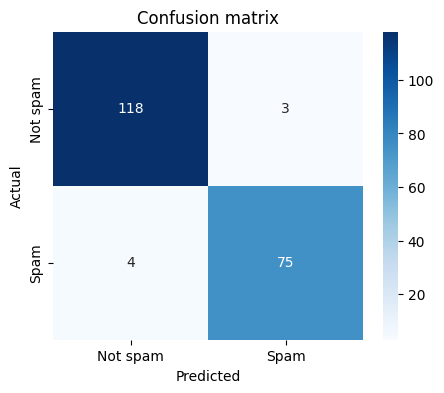

In [14]:
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not spam', 'Spam'], yticklabels=['Not spam', 'Spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix')
plt.show()

Reading the matrix: the top-left and bottom-right boxes are the correct predictions. The top-right box (false positives) are legitimate emails wrongly marked as spam, and the bottom-left box (false negatives) are spam emails that slipped into the inbox.

## Task 6: Precision, recall, F1-score and accuracy

In [15]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))

Accuracy : 0.965
Precision: 0.9615
Recall   : 0.9494
F1-score : 0.9554


In [16]:
print(classification_report(y_test, y_pred, target_names=['Not spam', 'Spam']))

              precision    recall  f1-score   support

    Not spam       0.97      0.98      0.97       121
        Spam       0.96      0.95      0.96        79

    accuracy                           0.96       200
   macro avg       0.96      0.96      0.96       200
weighted avg       0.96      0.96      0.96       200



What each metric means here (spam is the positive class):

- **Accuracy:** out of all test emails, the fraction classified correctly.
- **Precision:** out of all emails the model called spam, how many really were spam. Low precision means legitimate emails are being sent to spam.
- **Recall:** out of all the real spam emails, how many the model caught. Low recall means a lot of spam reaches the inbox.
- **F1-score:** the harmonic mean of precision and recall, a single number that is low if either of them is low.

Accuracy alone is not enough to judge this model. To show why, here is what a useless model that predicts "not spam" for every email would score:

In [17]:
baseline_accuracy = 1 - y_test.mean()
print("Accuracy of a model that always says 'not spam':", round(baseline_accuracy, 3))
print("Accuracy of our model                          :", round(accuracy, 3))
print("Spam emails caught by the always-'not spam' model: 0 out of", y_test.sum())

Accuracy of a model that always says 'not spam': 0.605
Accuracy of our model                          : 0.965
Spam emails caught by the always-'not spam' model: 0 out of 79


The "always not spam" model scores about 60% accuracy without catching a single spam email (recall = 0). Our model scores much higher, but the point is that accuracy hides the type of mistakes being made. Precision and recall tell us which mistakes they are, which is why we look at all of them.

## Task 7: Consequences of classifying a legitimate email as spam

This mistake is a **false positive**. In our results:

In [18]:
print(f"{fp} legitimate emails out of {tn + fp} were wrongly classified as spam.")
print(f"That is {fp / (tn + fp) * 100:.1f}% of all legitimate emails in the test set.")
print(f"Meanwhile {fn} spam emails out of {fn + tp} got through to the inbox.")

3 legitimate emails out of 121 were wrongly classified as spam.
That is 2.5% of all legitimate emails in the test set.
Meanwhile 4 spam emails out of 79 got through to the inbox.


**Consequences of a false positive (a legitimate email marked as spam):**

- **Missed important information.** The email goes to the spam folder, where most people never look. It could be a job interview call, an exam or fee notice, a bank alert, an OTP, an invoice or a message from a client.
- **Financial and business loss.** A missed order, a missed payment reminder or a delayed reply to a customer can cost real money or a relationship.
- **Missed deadlines and delays.** Time sensitive emails (meeting links, application deadlines) lose their value by the time the person finds them.
- **Loss of trust in the filter.** If users find out that real emails are ending up in spam, they start checking the spam folder every day (which defeats the purpose of the filter) or they stop trusting the system altogether.
- **Harder to notice.** The user never knows the email existed, and the sender usually does not know either, so the problem stays hidden, while a spam email in the inbox is at least visible and can be deleted in one click.

**Comparing it with a false negative** (spam reaching the inbox): it is annoying and in some cases dangerous (phishing links), but the user can see it and delete it. For this reason, in most real systems a false positive is considered the more costly mistake, so **precision** is given more weight than recall when tuning a spam filter. This does not mean recall is unimportant, since a filter that lets all the spam through is useless too.

**How the model can be made more careful:** the decision threshold can be raised from 0.5, so that an email is marked as spam only if the model is more confident. The cell below tries this.

In [19]:
rows = []
for threshold in [0.5, 0.7, 0.8, 0.9]:
    pred_t = (prob_spam >= threshold).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, pred_t).ravel()
    rows.append({'Threshold': threshold,
                 'Legit marked as spam (FP)': fp_t,
                 'Spam missed (FN)': fn_t,
                 'Accuracy': accuracy_score(y_test, pred_t),
                 'Precision': precision_score(y_test, pred_t),
                 'Recall': recall_score(y_test, pred_t)})

pd.DataFrame(rows).round(3)

,Threshold,Legit marked as spam (FP),Spam missed (FN),Accuracy,Precision,Recall
0,0.5,3,4,0.965,0.962,0.949
1,0.7,1,8,0.955,0.986,0.899
2,0.8,1,10,0.945,0.986,0.873
3,0.9,1,17,0.910,0.984,0.785


As the threshold goes up, fewer legitimate emails are marked as spam and precision increases, but more spam slips through and recall drops. There is always this trade-off. A company would pick the threshold depending on how costly each mistake is. For an email service where losing a real email is the worse outcome, a higher threshold like 0.7 or 0.8 is sensible. Another common practice is to send suspected spam to a spam folder (instead of deleting it) so that a wrongly filtered email can still be recovered.

---
## Conclusion

- A Logistic Regression model was trained on numerical email features to predict spam (1) or not spam (0).
- It outputs a probability of spam for each email, and the default threshold of 0.5 turns that into a label.
- On the test set it reached good accuracy, precision, recall and F1-score (see the results above), and only a small number of mistakes of each type.
- Accuracy alone cannot be trusted with imbalanced classes, so precision, recall and F1-score should always be checked as well.
- Marking a legitimate email as spam can cause missed jobs, payments and deadlines, so a spam filter should be tuned to keep false positives low, for example by raising the threshold.